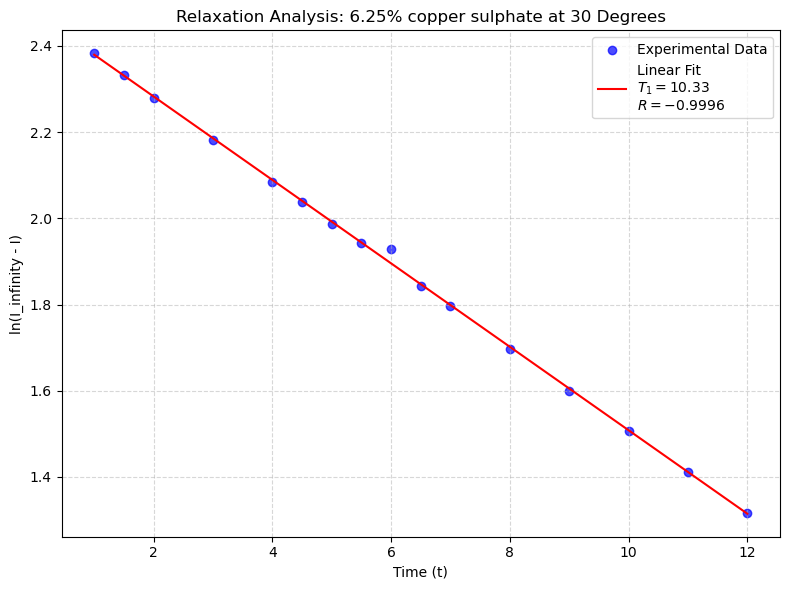

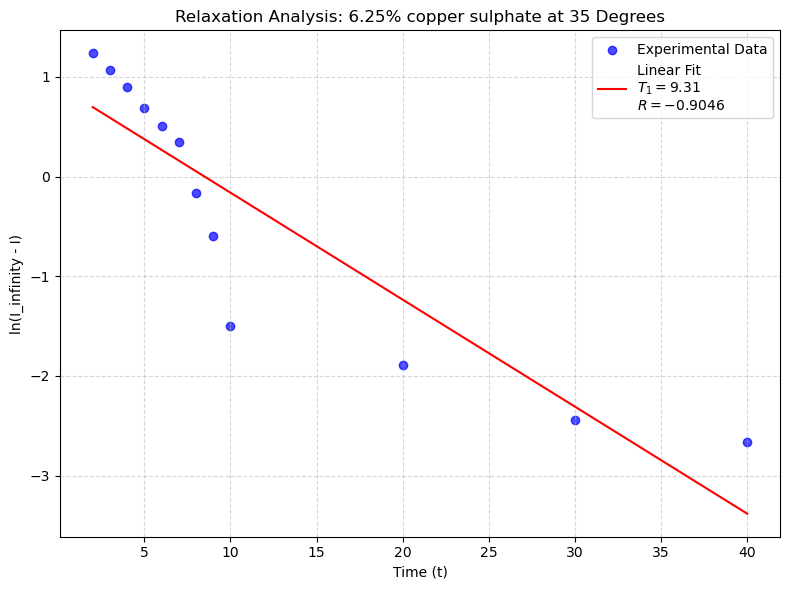

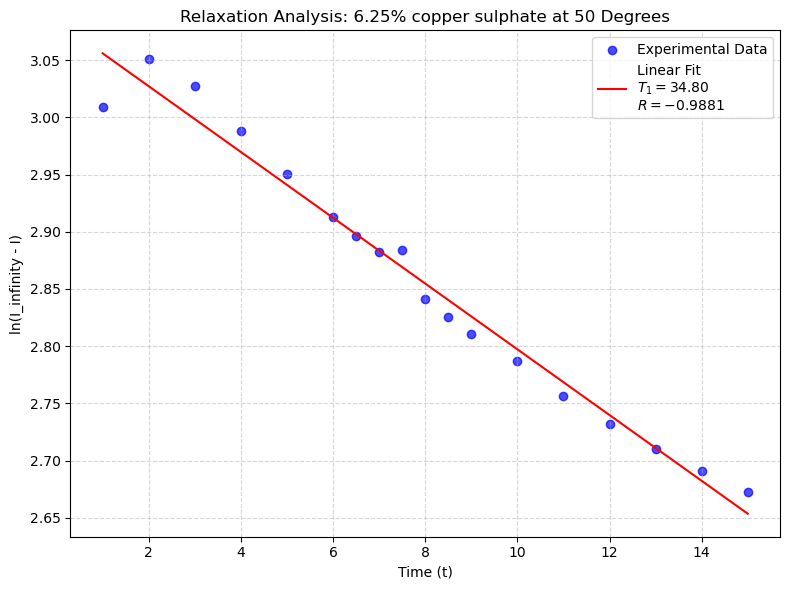

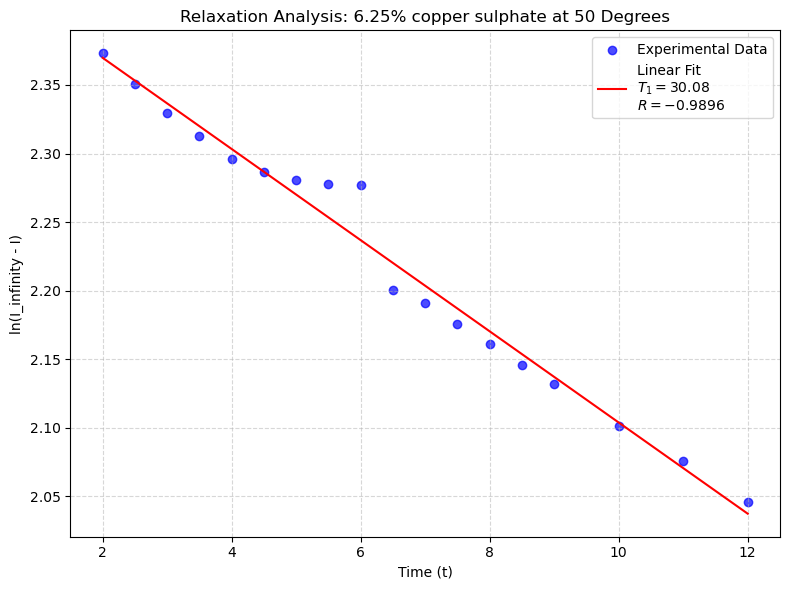

(np.float64(30.07859175220637), np.float64(-0.9895811874314596))

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress
from scipy.optimize import curve_fit

def analyze_t1(file_path, plot_title):
    """
    Analyzes T1 relaxation data from a CSV file.
    Uses the first 3 columns: Time, Voltage, and Std Dev.
    """
    # 1. Load data
    df = pd.read_csv(file_path)

    # 2. Extract first three columns and clean NaNs
    time = df.iloc[:, 0].values
    voltage = df.iloc[:, 1].values
    mask = ~np.isnan(time) & ~np.isnan(voltage)
    time, voltage = time[mask], voltage[mask]

    # 3. Determine the best Asymptote (I_infinity) for accurate linearization
    def model(t, A, B, T1):
        return A - B * np.exp(-t / T1)
    
    try:
        popt, _ = curve_fit(model, time, voltage, p0=[max(voltage)*1.1, 2*max(voltage), 25])
        I_inf = popt[0]
    except:
        I_inf = max(voltage) * 1.05 # Fallback if fit fails

    # 4. Linearization
    y_lin = np.log(I_inf - voltage)
    x_lin = time

    # 5. Linear Regression to get T1 and R
    res = linregress(x_lin, y_lin)
    t1_calc = -1 / res.slope
    r_val = res.rvalue

    # 6. Create the Plot
    plt.figure(figsize=(8, 6))
    plt.scatter(x_lin, y_lin, color='blue', label='Experimental Data', alpha=0.7)
    
    legend_info = f'Linear Fit\n$T_1 = {t1_calc:.2f}$\n$R = {r_val:.4f}$'
    plt.plot(x_lin, res.slope * x_lin + res.intercept, 'r-', label=legend_info)

    plt.xlabel("Time (t)")
    plt.ylabel("ln(I_infinity - I)")
    plt.title(plot_title)
    plt.legend(loc='best', frameon=True)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

    return t1_calc, r_val



def process_and_plot(filename, title):
    # 1. Load and Clean Data
    data = pd.read_csv(filename, encoding='windows-1252')
    data = data.iloc[:, 0:3].dropna()

    # Extract columns
    t = data.iloc[:, 0].values        
    V = data.iloc[:, 1].values   

    # Extract 3rd column (Standard Deviation) and convert mV to V
    std_dev = data.iloc[:, 2].values / 1000 
    std_dev = np.where(std_dev == 0, 1e-9, std_dev) # Prevent divide-by-zero errors

    # 2. Define the Mathematical Model
    def recovery_model(t, a, k, T1):
        return a - k * np.exp(-t / T1)

    # 3. Initial Guesses and Bounds
    p0 = [7.0, 14.0, 108.0]
    bounds = ([0, 0, 0], [20, 30, 300])

    # 4. Perform the Curve Fit
    popt, pcov = curve_fit(
        recovery_model, t, V, 
        p0=p0, 
        sigma=std_dev, 
        absolute_sigma=True,
        bounds=bounds
    )

    a_fit, k_fit, T1_fit = popt
    perr = np.sqrt(np.diag(pcov))
    a_err, k_err, T1_err = perr  

    print(f"--- Fit Results for {title} ---")
    print(f"Calculated T1: {T1_fit:.2f} ± {T1_err:.2f} ms")
    print(f"Fitted plateau (a): {a_fit:.2f} ± {a_err:.2f} V")
    print(f"Fitted amplitude (k): {k_fit:.2f} ± {k_err:.2f} V\n")

    # 5. Plotting the Graph
    plt.figure(figsize=(10, 6))

    # Plot raw data with highly visible red error bars
    plt.errorbar(t, V, yerr=std_dev, fmt='o', color='black', 
                 ecolor='red', elinewidth=1.5, capsize=4, capthick=1.5, 
                 label='Experimental Data', alpha=0.9, zorder=5)

    # Generate a smooth curve for the fitted line
    t_smooth = np.linspace(0, max(t) + 20, 200) 

    # Plot the best fit curve AND add the calculated error to the legend
    plt.plot(t_smooth, recovery_model(t_smooth, *popt), color='blue', linewidth=2, 
             label=f'Best Fit ($T_1$ = {T1_fit:.2f} $\pm$ {T1_err:.2f} ms)', zorder=3)

    # Formatting the graph
    plt.axhline(0, color='gray', linestyle='--', zorder=1)
    plt.xlim(0, max(t) + 10) 
    plt.xlabel('Delay Time (ms)', fontsize=12, fontweight='bold')
    plt.ylabel('Voltage (V)', fontsize=12, fontweight='bold')
    plt.title(title, fontsize=14, fontweight='bold')
    plt.legend(fontsize=12, loc='lower right')
    plt.grid(alpha=0.4, linestyle='--')

    # Show the plot instead of saving it 
    plt.tight_layout()
    plt.show()
analyze_t1(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\New folder\30\copper sulphate at 30.csv",  "Relaxation Analysis: 6.25% copper sulphate at 30 Degrees")

analyze_t1(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\New folder\35\T1 actual.csv",  "Relaxation Analysis: 6.25% copper sulphate at 35 Degrees")

analyze_t1(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\New folder\50\Book1.csv", "Relaxation Analysis: 6.25% copper sulphate at 50 Degrees")


analyze_t1(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\New folder\-10\T1.csv",  "Relaxation Analysis: 6.25% copper sulphate at -10 Degrees")